# 03 — Testes das hipóteses H1 e H2

- **H2:** postos de bandeira branca são mais baratos que os bandeirados.
- **H1:** quando o preço sobe em Maceió, o interior acompanha rápido; quando
  cai, demora mais ("rockets and feathers").

Só gasolina comum, com o de-para de bandeira do `load.py` (PETROBRAS
DISTRIBUIDORA / VIBRA ENERGIA / VIBRA → VIBRA; ALESAT / ALE → ALE).
Resultados agregados por município e bandeira — sem nomes de postos.
Conclusões valem para os postos pesquisados pela ANP, não para o mercado inteiro.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))
from series import carregar_comum, painel_municipios, indice_estadual, preco_posto_semana

DOCS = RAIZ / "docs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

comum = carregar_comum()
preco, n_postos = painel_municipios(comum)
indice = indice_estadual(preco)
ULTIMA_COLETA = comum["data_coleta"].max()
print(f"gasolina comum: {len(comum):,} linhas | semanas no calendário: {len(preco)}")
print(f"dado mais recente: coleta de {ULTIMA_COLETA:%d/%m/%Y}")
print(f"semanas com índice estadual definido: {indice.notna().sum()} de {len(indice)}")

gasolina comum: 19,366 linhas | semanas no calendário: 400
dado mais recente: coleta de 26/08/2026
semanas com índice estadual definido: 369 de 400


## H2 — bandeira branca × bandeirada

Comparar médias gerais misturaria município e época (Maceió tem mais postos
bandeirados e preços diferentes do interior). Por isso a comparação é feita
**dentro do mesmo município e da mesma semana**: em cada célula
município × semana com pelo menos 2 postos de cada tipo, calcula-se
preço médio branca − preço médio bandeirada.

In [2]:
ps = preco_posto_semana(comum)
cel = (ps.groupby(["semana", "municipio", "bandeira_branca"])["valor_venda"]
         .agg(["mean", "size"]).unstack().dropna())
cel = cel[(cel[("size", True)] >= 2) & (cel[("size", False)] >= 2)]
dif = ((cel[("mean", True)] - cel[("mean", False)]) * 100).rename("dif_centavos")

por_semana = dif.groupby(level="semana").mean()
rng = np.random.default_rng(0)
boot = [rng.choice(por_semana.to_numpy(), len(por_semana)).mean() for _ in range(5000)]
ic = np.percentile(boot, [2.5, 97.5])

print(f"células município × semana comparáveis: {len(dif)}")
print(f"diferença média por semana (branca − bandeirada): {por_semana.mean():.1f} centavos/litro")
print(f"mediana: {dif.median():.1f} | branca mais barata em {(dif < 0).mean():.0%} das células")
print(f"IC 95% (bootstrap por semana): [{ic[0]:.1f}; {ic[1]:.1f}]")
resumo = dif.groupby(level="municipio").agg(media="mean", mediana="median", celulas="count",
                                           branca_mais_barata=lambda x: (x < 0).mean())
resumo.round(2)

células município × semana comparáveis: 1263
diferença média por semana (branca − bandeirada): -7.4 centavos/litro
mediana: -4.7 | branca mais barata em 85% das células
IC 95% (bootstrap por semana): [-7.9; -6.9]


,media,mediana,celulas,branca_mais_barata
municipio,,,,
ARAPIRACA,-9.09,-7.31,360,0.83
DELMIRO GOUVEIA,-3.04,-2.85,314,0.87
MACEIO,-6.87,-5.47,362,0.85
PALMEIRA DOS INDIOS,-8.06,-6.67,130,0.85
RIO LARGO,-9.24,-7.30,97,0.91


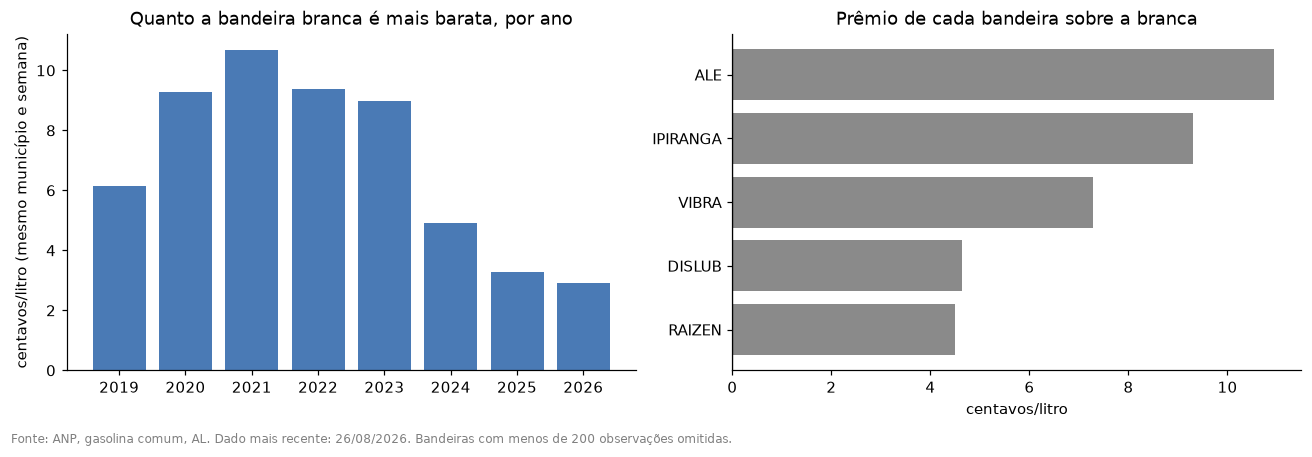

,mean,count
semana,,
2019,-6.1,186
2020,-9.3,141
2021,-10.7,130
2022,-9.4,181
2023,-9.0,152
2024,-4.9,154
2025,-3.3,191
2026,-2.9,124


In [3]:
por_ano = dif.groupby(dif.index.get_level_values("semana").year).agg(["mean", "count"])
por_ano = por_ano[por_ano["count"] >= 20]  # 2018 tem só a semana de 31/12

# cada bandeira contra a média branca da mesma célula município × semana
branca = ps[ps["bandeira_branca"]].groupby(["semana", "municipio"])["valor_venda"].mean().rename("branca")
comp = ps[~ps["bandeira_branca"]].join(branca, on=["semana", "municipio"], how="inner")
comp["dif"] = (comp["valor_venda"] - comp["branca"]) * 100
por_bandeira = comp.groupby("bandeira_grupo")["dif"].agg(["mean", "count"])
por_bandeira = por_bandeira[por_bandeira["count"] >= 200].sort_values("mean")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.bar(por_ano.index.astype(str), -por_ano["mean"], color="#4a7ab5")
a1.set_title("Quanto a bandeira branca é mais barata, por ano")
a1.set_ylabel("centavos/litro (mesmo município e semana)")
a2.barh(por_bandeira.index, por_bandeira["mean"], color="#8a8a8a")
a2.axvline(0, color="black", lw=0.8)
a2.set_title("Prêmio de cada bandeira sobre a branca")
a2.set_xlabel("centavos/litro")
fig.text(0.01, -0.02, f"Fonte: ANP, gasolina comum, AL. Dado mais recente: {ULTIMA_COLETA:%d/%m/%Y}. "
         "Bandeiras com menos de 200 observações omitidas.", fontsize=8, color="gray")
fig.tight_layout()
fig.savefig(DOCS / "fig_h2_bandeira.png", bbox_inches="tight")
plt.show()
por_ano.round(1)

**Resultado H2 — confirmada.** Na mesma cidade e semana, a bandeira branca
sai em média ~7 centavos/litro (IC 95%: 6,9 a 7,9) mais barata e é a mais barata em ~85% das
comparações, nos cinco municípios. A vantagem **vem encolhendo**: ~10 centavos
em 2021–2022, ~3 centavos em 2025–2026. Entre as bandeiradas, ALE e Ipiranga
têm o maior prêmio; Raízen e Dislub, o menor.

## H1 — assimetria de repasse Maceió → interior

Regressão da variação semanal do preço no município do interior sobre as
variações de Maceió separadas em **altas** e **quedas**, com 0 a 3 semanas de
defasagem, mais um lag da própria variação. Erros-padrão HAC (Newey-West, 4 lags).

Se H1 vale, o repasse acumulado das altas deveria ser maior e mais rápido que o
das quedas. Arapiraca e Delmiro Gouveia são os municípios do interior com
cobertura suficiente; Palmeira dos Índios e Rio Largo somem em 2021 inteiro.

ARAPIRACA: 345 semanas | p(alta=queda na semana 0) = 0.31 | p(repasse total igual) = 0.57
DELMIRO GOUVEIA: 294 semanas | p(alta=queda na semana 0) = 0.28 | p(repasse total igual) = 0.23


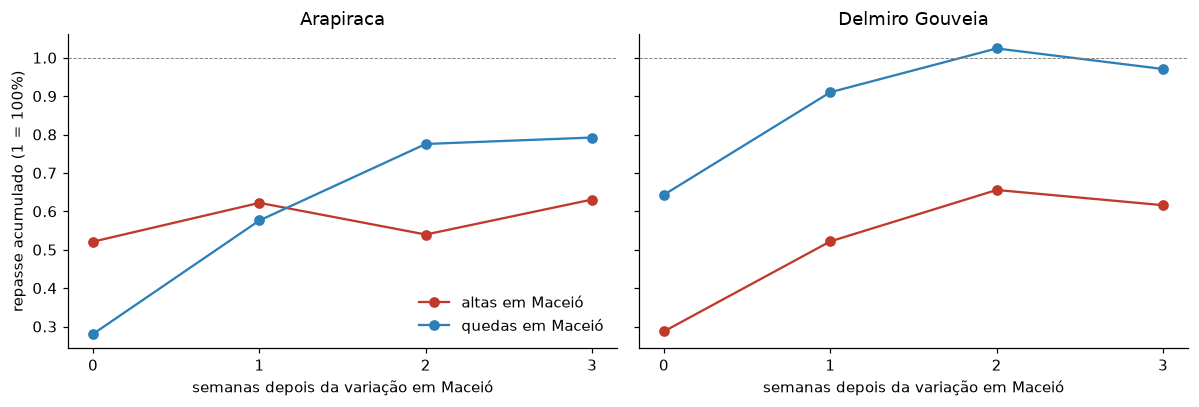

,municipio,semanas,repasse_alta,repasse_queda
0,ARAPIRACA,0,0.52,0.28
1,ARAPIRACA,1,0.62,0.58
2,ARAPIRACA,2,0.54,0.78
3,ARAPIRACA,3,0.63,0.79
4,DELMIRO GOUVEIA,0,0.29,0.64
5,DELMIRO GOUVEIA,1,0.52,0.91
6,DELMIRO GOUVEIA,2,0.66,1.02
7,DELMIRO GOUVEIA,3,0.62,0.97


In [4]:
import statsmodels.api as sm

dm = preco["MACEIO"].diff()
linhas = []
for mun in ["ARAPIRACA", "DELMIRO GOUVEIA"]:
    dy = preco[mun].diff()
    X = pd.DataFrame({**{f"alta_{k}": dm.clip(lower=0).shift(k) for k in range(4)},
                      **{f"queda_{k}": dm.clip(upper=0).shift(k) for k in range(4)},
                      "lag_proprio": dy.shift(1)})
    df = pd.concat([dy.rename("y"), X], axis=1).dropna()
    r = sm.OLS(df["y"], sm.add_constant(df.drop(columns="y"))).fit(
        cov_type="HAC", cov_kwds={"maxlags": 4})
    alta = np.cumsum([r.params[f"alta_{k}"] for k in range(4)])
    queda = np.cumsum([r.params[f"queda_{k}"] for k in range(4)])
    p0 = float(r.wald_test("alta_0 = queda_0", scalar=True).pvalue)
    p_tot = float(r.wald_test("alta_0 + alta_1 + alta_2 + alta_3 = queda_0 + queda_1 + queda_2 + queda_3",
                              scalar=True).pvalue)
    for k in range(4):
        linhas.append({"municipio": mun, "semanas": k, "repasse_alta": alta[k], "repasse_queda": queda[k]})
    print(f"{mun}: {len(df)} semanas | p(alta=queda na semana 0) = {p0:.2f} | p(repasse total igual) = {p_tot:.2f}")

rep = pd.DataFrame(linhas)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (mun, g) in zip(axs, rep.groupby("municipio")):
    ax.plot(g["semanas"], g["repasse_alta"], "o-", color="#c0392b", label="altas em Maceió")
    ax.plot(g["semanas"], g["repasse_queda"], "o-", color="#2c7fb8", label="quedas em Maceió")
    ax.axhline(1, color="gray", lw=0.6, ls="--")
    ax.set_title(mun.title()); ax.set_xlabel("semanas depois da variação em Maceió")
    ax.set_xticks(range(4))
axs[0].set_ylabel("repasse acumulado (1 = 100%)")
axs[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(DOCS / "fig_h1_repasse.png", bbox_inches="tight")
plt.show()
rep.round(2)

**Resultado H1 — não confirmada.** Em Arapiraca a alta de Maceió chega um
pouco mais rápido na primeira semana do que a queda, na direção da hipótese,
mas a diferença não é estatisticamente significativa (p ≈ 0,3), e já na semana 1
o repasse das quedas alcança o das altas e depois passa à frente. Em Delmiro Gouveia o padrão é o inverso. Com esta
amostra não há evidência de "rockets and feathers" entre Maceió e o interior.

Limitação: a mediana semanal de 7–14 postos no interior tem bastante ruído
amostral, o que reduz o poder do teste. Ausência de evidência não é evidência de
ausência.